# 01 – Dataset and Exploratory Data Analysis

**Dataset:** UJIIndoorLoc (UCI ML Repository, CC BY 4.0)

**Goal:** show that the dataset is understood, reliable, and appropriate for predicting
building, floor and coordinates from Wi-Fi fingerprints.

**What one row is:** a single Wi-Fi scan taken by one phone at one location. It records the
signal strength (RSSI) of 520 access points (WAPs), the true location (building, floor,
longitude, latitude), and metadata about who took it, with which phone, and when.

**Rule for this notebook:** we *describe* the validation file but never use its labels to make
modelling decisions. It is our held-out test set.

## Contents
1. Setup and loading
2. Dataset overview and summary table
3. Data-quality checks
4. Label distributions and class imbalance
5. Signal strength and spatial coverage
6. Users, devices, train vs validation shift, and leakage risks
7. Summary and recommendations for the team

## 1. Setup and loading

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make `src/` importable when the notebook runs from notebooks/
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from src.data_loader import (
    load_train, load_validation, split_columns,
    WAP_COLS, TARGET_COLS, META_COLS, MISSING_RSSI,
)

FIG_DIR = REPO_ROOT / "results" / "figures"
METRICS_DIR = REPO_ROOT / "results" / "metrics"
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

In [2]:
train = load_train()
val = load_validation()

X_tr, y_tr, meta_tr = split_columns(train)
X_va, y_va, meta_va = split_columns(val)

print("Train:     ", train.shape)
print("Validation:", val.shape)

Train:      (19937, 529)
Validation: (1111, 529)


In [3]:
# The last 9 (non-WAP) columns
train[TARGET_COLS + META_COLS].head()

,BUILDINGID,FLOOR,LONGITUDE,LATITUDE,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,1,2,-7541.2643,4.864921e+06,106,2,2,23,1371713733
1,1,2,-7536.6212,4.864934e+06,106,2,2,23,1371713691
2,1,2,-7519.1524,4.864950e+06,103,2,2,23,1371714095
3,1,2,-7524.5704,4.864934e+06,102,2,2,23,1371713807
4,0,0,-7632.1436,4.864982e+06,122,2,11,13,1369909710


## 2. Dataset overview

The 529 columns split into three groups:

| Group | Columns | Use |
|---|---|---|
| Inputs | `WAP001`–`WAP520` | RSSI in dBm (−104 to 0), or **100 = not detected** |
| Targets | `BUILDINGID`, `FLOOR` (classification); `LONGITUDE`, `LATITUDE` (regression) | What we predict |
| Metadata | `SPACEID`, `RELATIVEPOSITION`, `USERID`, `PHONEID`, `TIMESTAMP` | Robustness and leakage analysis only |

In [4]:
def n_detected(X):
    """Number of access points actually detected in each scan."""
    return (X != MISSING_RSSI).sum(axis=1)

def summarise(df, X, name):
    det = n_detected(X)
    ts = pd.to_datetime(df["TIMESTAMP"], unit="s")
    return {
        "split": name,
        "rows": len(df),
        "columns": df.shape[1],
        "WAP columns": len(WAP_COLS),
        "buildings": df["BUILDINGID"].nunique(),
        "floors": df["FLOOR"].nunique(),
        "building-floor pairs": df.groupby(["BUILDINGID", "FLOOR"]).ngroups,
        "users": df["USERID"].nunique(),
        "phones": df["PHONEID"].nunique(),
        "first capture": ts.min().date(),
        "last capture": ts.max().date(),
        "% WAP cells = 100 (not detected)": round(100 * (X == MISSING_RSSI).values.mean(), 2),
        "mean APs detected per scan": round(det.mean(), 1),
        "median APs detected per scan": int(det.median()),
        "scans with 0 APs detected": int((det == 0).sum()),
        "exact duplicate rows": int(df.duplicated().sum()),
        "null values": int(df.isna().sum().sum()),
    }

summary = pd.DataFrame([summarise(train, X_tr, "train"),
                        summarise(val, X_va, "validation")]).set_index("split").T
summary.to_csv(METRICS_DIR / "eda_dataset_summary.csv")
summary

split,train,validation
rows,19937,1111
columns,529,529
WAP columns,520,520
buildings,3,3
floors,5,5
building-floor pairs,13,13
users,18,1
phones,16,11
first capture,2013-05-30,2013-09-19
last capture,2013-06-20,2013-10-08


**Reading the summary**

- The dataset has **no NaN values**, but that is misleading: absent access points are encoded as
  `100`, so the data is in fact extremely sparse. Most WAP cells are "not detected".
- A typical scan sees only a small fraction of the 520 access points. This sparsity is the core
  modelling challenge and the reason preprocessing (Member 3) must treat `100` explicitly.
- The two files were collected on different dates, so some distribution shift between them is expected.

## 3. Data-quality checks

### 3.1 RSSI values are within the documented range

In [5]:
def rssi_value_check(X, name):
    v = X.values.ravel()
    observed = v[v != MISSING_RSSI]
    return {
        "split": name,
        "min observed RSSI": int(observed.min()),
        "max observed RSSI": int(observed.max()),
        "values outside [-104, 0] (excl. 100)": int(((observed < -104) | (observed > 0)).sum()),
    }

pd.DataFrame([rssi_value_check(X_tr, "train"), rssi_value_check(X_va, "validation")]).set_index("split")

,min observed RSSI,max observed RSSI,"values outside [-104, 0] (excl. 100)"
split,,,
train,-104,0,0
validation,-102,-34,0


Every real measurement should lie between −104 and 0 dBm. Any non-zero count in the last column
indicates corrupted values that must be reported. Note that `100` is **not** a strong signal:
real RSSI is always ≤ 0, and values closer to 0 mean *stronger* signals.

### 3.2 Label validity

In [6]:
for name, df in [("train", train), ("validation", val)]:
    print(f"{name}: buildings = {sorted(df['BUILDINGID'].unique().tolist())}, floors = {sorted(df['FLOOR'].unique().tolist())}")

# Which floors exist in each building?
floors_per_building = (
    pd.concat([train[["BUILDINGID", "FLOOR"]].assign(split="train"),
               val[["BUILDINGID", "FLOOR"]].assign(split="validation")])
      .groupby(["split", "BUILDINGID"])["FLOOR"]
      .apply(lambda s: sorted(s.unique().tolist()))
      .unstack("split")
)
floors_per_building

train: buildings = [0, 1, 2], floors = [0, 1, 2, 3, 4]
validation: buildings = [0, 1, 2], floors = [0, 1, 2, 3, 4]


split,train,validation
BUILDINGID,,
0,"[0, 1, 2, 3]","[0, 1, 2, 3]"
1,"[0, 1, 2, 3]","[0, 1, 2, 3]"
2,"[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]"


Buildings should be 0–2 and floors 0–4. Floor 4 should appear only in building 2, the one
building with five floors. A floor label of 4 in buildings 0 or 1 would be invalid.

In [7]:
invalid = train[(train["FLOOR"] == 4) & (train["BUILDINGID"] != 2)]
print("Train rows with floor 4 outside building 2:", len(invalid))

# Coordinate ranges per building (sanity check that buildings are spatially separate)
train.groupby("BUILDINGID")[["LONGITUDE", "LATITUDE"]].agg(["min", "max"]).round(1)

Train rows with floor 4 outside building 2: 0


LONGITUDE           LATITUDE           
                 min     max        min        max
BUILDINGID                                        
0            -7691.3 -7587.0  4864897.5  4865016.7
1            -7578.5 -7404.5  4864810.0  4864959.5
2            -7415.2 -7300.8  4864745.7  4864861.8

### 3.3 Duplicates

In [8]:
dup_full = train.duplicated()
dup_fp_label = train.duplicated(subset=WAP_COLS + TARGET_COLS)
dup_fp_only = train.duplicated(subset=WAP_COLS)

print(f"Exact duplicate rows (all 529 columns):        {dup_full.sum():>5}")
print(f"Same fingerprint + same location:               {dup_fp_label.sum():>5}")
print(f"Same fingerprint, any location:                 {dup_fp_only.sum():>5}")
print(f"Validation exact duplicates:                    {val.duplicated().sum():>5}")

Exact duplicate rows (all 529 columns):          637
Same fingerprint + same location:                 754
Same fingerprint, any location:                   852
Validation exact duplicates:                        0


In [9]:
# Identical fingerprints labelled with DIFFERENT locations are ambiguous for any model.
# Empty scans (0 APs detected) are excluded here; they are covered in section 3.4.
has_signal = n_detected(X_tr) > 0
same_fp = train[has_signal & train.duplicated(subset=WAP_COLS, keep=False)]
conflicting = (
    same_fp.groupby(WAP_COLS)[["BUILDINGID", "FLOOR"]]
           .nunique()
           .max(axis=1)
)
print("Distinct fingerprints that map to more than one building/floor:",
      int((conflicting > 1).sum()))

Distinct fingerprints that map to more than one building/floor: 0


Exact duplicates usually arise from repeated scans at the same reference point. They inflate the
apparent dataset size and can leak information if one copy lands in a training fold and another in a
validation fold.

**Finding:** 637 exact duplicate rows (3.2% of train). A further 117 scans repeat a fingerprint and its
location but differ in metadata (e.g. timestamp). Importantly, **no fingerprint with signal maps to two
different building/floor labels**, so the duplicates are redundant rather than contradictory.
**The team should decide together whether to drop them** (Member 3 implements this; Member 4 must use
the same choice for cross-validation).

### 3.4 Scans with no detected access points

In [10]:
det_tr = n_detected(X_tr)
det_va = n_detected(X_va)

zero_tr = train[det_tr == 0]
print("Train scans with 0 APs:     ", len(zero_tr))
print("Validation scans with 0 APs:", int((det_va == 0).sum()))

if len(zero_tr):
    display(zero_tr.groupby(["BUILDINGID", "FLOOR"]).size().rename("zero-AP scans").to_frame())
    display(zero_tr.groupby(["USERID", "PHONEID"]).size().rename("zero-AP scans").to_frame())

Train scans with 0 APs:      76
Validation scans with 0 APs: 0


zero-AP scans
BUILDINGID FLOOR               
0          0                  1
1          3                 37
2          0                 36
           1                  1
           2                  1

,,zero-AP scans
USERID,PHONEID,
7,6,1
8,1,59
11,13,2
17,22,14


A scan with no detected access points carries **no Wi-Fi information**, so no model can locate it.

**Finding:** all 76 empty scans are in the training file, and **59 of them (78%) come from a single
user/phone (USERID 8, PHONEID 1)**, concentrated in building 1 floor 3 and building 2 floor 0.
This points to a faulty collection session, not a property of those locations. These rows should be
removed from training; the validation file has none.

### 3.5 Access points never detected

In [11]:
seen_tr = (X_tr != MISSING_RSSI).any(axis=0)
seen_va = (X_va != MISSING_RSSI).any(axis=0)

wap_coverage = pd.Series({
    "WAPs seen in train": int(seen_tr.sum()),
    "WAPs seen in validation": int(seen_va.sum()),
    "never seen in train (constant columns)": int((~seen_tr).sum()),
    "seen in validation but NOT in train": int((seen_va & ~seen_tr).sum()),
    "seen in train but NOT in validation": int((seen_tr & ~seen_va).sum()),
    "never seen anywhere": int((~seen_tr & ~seen_va).sum()),
}, name="count")
wap_coverage.to_frame()

,count
WAPs seen in train,465
WAPs seen in validation,367
never seen in train (constant columns),55
seen in validation but NOT in train,55
seen in train but NOT in validation,153
never seen anywhere,0


- **Never seen in train:** these columns are constant (always 100) in training data, so a model
  cannot learn anything from them. They can be dropped. The decision must be based on the
  **training file only**.
- **Seen in validation but not in train:** access points that appear at test time but were
  never available to learn from. This is one concrete form of train/validation shift and
  will be explored further in stage 4.

In [12]:
never_seen_train = [c for c in WAP_COLS if not seen_tr[c]]
print(f"{len(never_seen_train)} constant WAP columns in train, e.g. {never_seen_train[:8]}")

55 constant WAP columns in train, e.g. ['WAP003', 'WAP004', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP152', 'WAP158']


### 3.6 Metadata placeholders in the validation file

In [13]:
for col in ["SPACEID", "RELATIVEPOSITION", "USERID"]:
    print(f"{col:<17} train unique: {train[col].nunique():>4}   validation unique values: {sorted(val[col].unique().tolist())}")
print(f"{'PHONEID':<17} phones in both files: {sorted(set(train['PHONEID']) & set(val['PHONEID']))}")

SPACEID           train unique:  123   validation unique values: [0]
RELATIVEPOSITION  train unique:    2   validation unique values: [0]
USERID            train unique:   18   validation unique values: [0]
PHONEID           phones in both files: [13, 14]


In the validation file, `SPACEID`, `RELATIVEPOSITION` and `USERID` are placeholders (all 0), so
they cannot be used as features. User-grouped robustness splits are possible **only within the
training file**.

**Finding:** the validation file uses 11 phones, but **only 2 of them (PHONEID 13 and 14) also appear in
training**. Different phones report different RSSI for the same location, so the validation set tests
generalisation to largely *unseen devices*. This, together with the 3-month gap between collections and
the access points that appear only in validation, means validation errors will be higher than
cross-validation errors within the training file. That is expected and is not a modelling bug.

## Stage 1 findings

| Check | Result | Action / owner |
|---|---|---|
| Missing values | No NaNs; absence encoded as `100` (96.5% of WAP cells in train, 96.8% in validation) | Member 3: impute consistently |
| Sparsity | Median 17 of 520 APs detected per scan in train, 15 in validation | Core modelling challenge |
| RSSI range | 0 values outside [−104, 0] dBm in either file | None needed |
| Labels | Buildings 0–2, floors 0–4, floor 4 only in building 2; 13 building–floor pairs in both files | None needed |
| Spatial separation | Coordinate ranges of the 3 buildings barely overlap | Building is well defined |
| Duplicates | 637 exact duplicate rows in train (3.2%); none conflicting; 0 in validation | Team decision: drop or keep |
| Zero-AP scans | 76 in train (59 from USERID 8 / PHONEID 1), 0 in validation | Remove from training |
| Constant WAPs | 55 never detected in train | Member 3: drop these columns |
| WAPs absent from validation | 153 seen in train but never in validation | Note: these features carry no signal at test time |
| Unseen-in-train WAPs | The same 55 appear only in validation | Distribution shift; cannot be learned |
| Devices | Only 2 of the 11 validation phones appear in train | Distribution shift; explains higher test error |
| Collection dates | Train 30 May – 20 Jun 2013; validation 19 Sep – 8 Oct 2013 | Temporal shift |
| Validation metadata | `USERID`, `SPACEID`, `RELATIVEPOSITION` are placeholders (0) | Grouped splits within train only |

## 4. Label distributions and class imbalance

Why this matters: if one class dominates, a model can score high accuracy by favouring it while
failing on rare classes. That is why Member 5 reports **macro-F1** for floors, not just accuracy.

The validation label distribution is shown for **description only**. It is not used for any
modelling decision.

In [14]:
# Shared plot style (used by all EDA figures)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "legend.frameon": False,
    "font.size": 10,
})

# Fixed colours: same split / building / floor always gets the same colour in every figure
SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eb6834"}
BUILDING_COLORS = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
FLOOR_COLORS = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a", 3: "#eda100", 4: "#e87ba4"}
TEXT = "#52514e"

def save(fig, name):
    path = FIG_DIR / f"eda_{name}.png"
    fig.savefig(path)
    print("saved", path.relative_to(REPO_ROOT))

### 4.1 Samples per building

count            % of split           
           train validation      train validation
BUILDINGID                                       
0           5249        536       26.3       48.2
1           5196        307       26.1       27.6
2           9492        268       47.6       24.1

saved results/figures/eda_samples_per_building.png


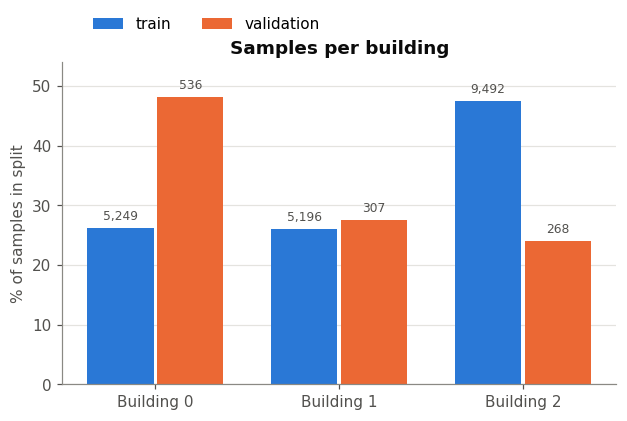

In [15]:
bld = pd.DataFrame({
    "train": train["BUILDINGID"].value_counts().sort_index(),
    "validation": val["BUILDINGID"].value_counts().sort_index(),
})
bld_pct = (bld / bld.sum() * 100).round(1)
display(pd.concat({"count": bld, "% of split": bld_pct}, axis=1))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(len(bld))
w = 0.36
for i, split in enumerate(["train", "validation"]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), bld_pct[split], width=w,
                  color=SPLIT_COLORS[split], label=split)
    for b, n in zip(bars, bld[split]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{n:,}",
                ha="center", va="bottom", fontsize=8, color=TEXT)
ax.set_xticks(x, [f"Building {b}" for b in bld.index])
ax.set_ylabel("% of samples in split")
ax.set_title("Samples per building")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=1.6)
ax.set_ylim(0, bld_pct.values.max() * 1.12)
save(fig, "samples_per_building")
plt.show()

Bars show the **share** of each split so that train (19,937 rows) and validation (1,111 rows) are
comparable on one axis; the number above each bar is the raw count.

**Finding:** the two files are distributed very differently across buildings. Training is dominated by
building 2 (47.6% of scans; building 0 26.3%, building 1 26.1%), while validation is dominated by
building 0 (48.2%; building 1 27.6%, building 2 24.1%). Overall validation accuracy will therefore be
driven mostly by how well models do in building 0, which is why Member 5's building-wise breakdown matters.

### 4.2 Samples per floor, within each building

In [16]:
bf_train = pd.crosstab(train["BUILDINGID"], train["FLOOR"])
bf_val = pd.crosstab(val["BUILDINGID"], val["FLOOR"])
print("Train counts (rows = building, columns = floor)")
display(bf_train)
print("Validation counts")
display(bf_val)

Train counts (rows = building, columns = floor)


FLOOR,0,1,2,3,4
BUILDINGID,,,,,
0,1059,1356,1443,1391,0
1,1368,1484,1396,948,0
2,1942,2162,1577,2709,1102


Validation counts


FLOOR,0,1,2,3,4
BUILDINGID,,,,,
0,78,208,165,85,0
1,30,143,87,47,0
2,24,111,54,40,39


saved results/figures/eda_samples_per_floor.png


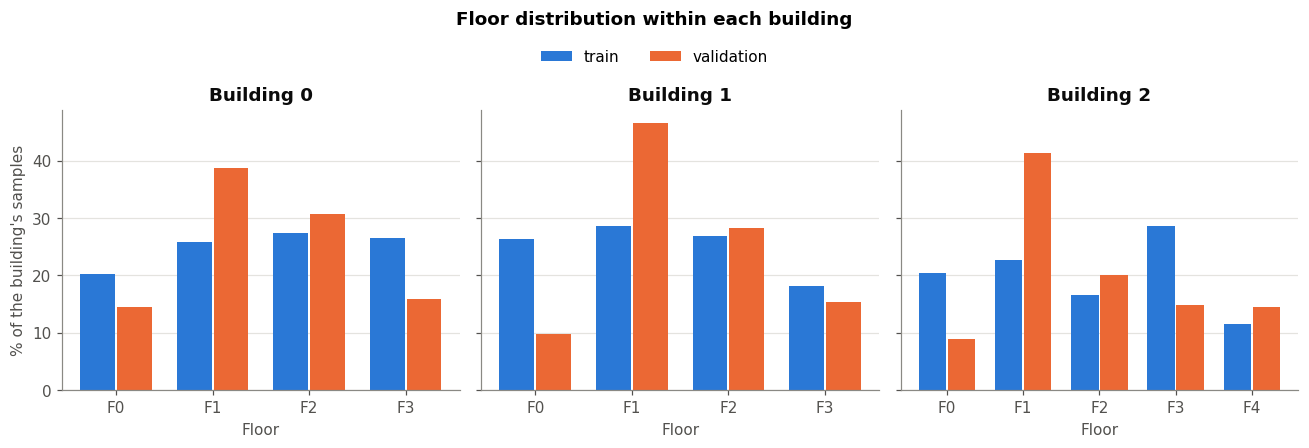

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, b in zip(axes, sorted(train["BUILDINGID"].unique())):
    floors = sorted(train.loc[train["BUILDINGID"] == b, "FLOOR"].unique())
    tr = train.loc[train["BUILDINGID"] == b, "FLOOR"].value_counts(normalize=True).reindex(floors, fill_value=0) * 100
    va = val.loc[val["BUILDINGID"] == b, "FLOOR"].value_counts(normalize=True).reindex(floors, fill_value=0) * 100
    x = np.arange(len(floors))
    w = 0.36
    ax.bar(x - (w + 0.02) / 2, tr, width=w, color=SPLIT_COLORS["train"], label="train")
    ax.bar(x + (w + 0.02) / 2, va, width=w, color=SPLIT_COLORS["validation"], label="validation")
    ax.set_xticks(x, [f"F{f}" for f in floors])
    ax.set_title(f"Building {b}")
    ax.set_xlabel("Floor")
axes[0].set_ylabel("% of the building's samples")
fig.suptitle("Floor distribution within each building", fontweight="bold", y=1.06)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout()
save(fig, "samples_per_floor")
plt.show()

Floors are compared **within** each building because building 2 has five floors (0–4) while buildings
0 and 1 have four. Part of the floor imbalance is therefore structural: floor 4 can only ever come from
one building.

**Finding:** within buildings, the training floors are reasonably spread, but the smallest floors are
building 1 floor 3 (948 scans) and building 2 floor 4 (1,102). The validation floors are far more uneven:
floor 1 alone makes up 41.6% of validation scans, while building 1 floor 0 (30 scans) and building 2
floor 0 (24 scans) are barely represented. Per-floor validation scores for these small groups will be noisy.

### 4.3 The 13 building–floor classes

In [18]:
keys = ["BUILDINGID", "FLOOR"]
samples = train.groupby(keys).size().rename("samples")

# A reference point = a unique (longitude, latitude) position where scans were taken
ref_pts = (train[keys + ["LONGITUDE", "LATITUDE"]].drop_duplicates()
                .groupby(keys).size().rename("reference_points"))

classes = pd.concat([samples, ref_pts], axis=1).reset_index()
classes["samples_per_point"] = (classes["samples"] / classes["reference_points"]).round(1)
classes["% of train"] = (classes["samples"] / len(train) * 100).round(1)
classes["label"] = "B" + classes["BUILDINGID"].astype(str) + "-F" + classes["FLOOR"].astype(str)
display(classes.set_index("label"))

,BUILDINGID,FLOOR,samples,reference_points,samples_per_point,% of train
label,,,,,,
B0-F0,0,0,1059,54,19.6,5.3
B0-F1,0,1,1356,67,20.2,6.8
B0-F2,0,2,1443,70,20.6,7.2
B0-F3,0,3,1391,68,20.5,7.0
B1-F0,1,0,1368,76,18.0,6.9
B1-F1,1,1,1484,60,24.7,7.4
B1-F2,1,2,1396,79,17.7,7.0
B1-F3,1,3,948,50,19.0,4.8
B2-F0,2,0,1942,67,29.0,9.7


saved results/figures/eda_building_floor_classes.png


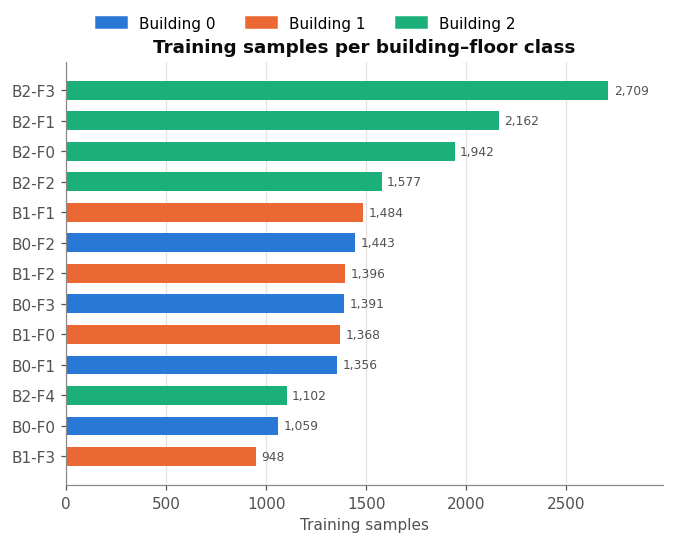

In [19]:
order = classes.sort_values("samples", ascending=True)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(order["label"], order["samples"], height=0.62,
        color=[BUILDING_COLORS[b] for b in order["BUILDINGID"]])
for y, n in enumerate(order["samples"]):
    ax.text(n + order["samples"].max() * 0.01, y, f"{n:,}", va="center", fontsize=8, color=TEXT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Training samples")
ax.set_title("Training samples per building–floor class")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f"Building {b}") for b, c in BUILDING_COLORS.items()],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, borderaxespad=1.6)
ax.set_xlim(0, order["samples"].max() * 1.1)
save(fig, "building_floor_classes")
plt.show()

### 4.4 Imbalance summary

In [20]:
def imbalance(counts):
    counts = counts[counts > 0]
    return {
        "classes": len(counts),
        "largest class": int(counts.max()),
        "smallest class": int(counts.min()),
        "imbalance ratio (largest / smallest)": round(counts.max() / counts.min(), 2),
        "majority-class accuracy (%)": round(counts.max() / counts.sum() * 100, 1),
    }

imb = pd.DataFrame({
    "building": imbalance(train["BUILDINGID"].value_counts()),
    "floor (all buildings)": imbalance(train["FLOOR"].value_counts()),
    "building–floor (13 classes)": imbalance(train.groupby(["BUILDINGID", "FLOOR"]).size()),
}).T.astype(object)
for c in ["classes", "largest class", "smallest class"]:
    imb[c] = imb[c].astype(int)
imb.to_csv(METRICS_DIR / "eda_class_imbalance.csv")
imb

,classes,largest class,smallest class,imbalance ratio (largest / smallest),majority-class accuracy (%)
building,3,9492,5196,1.83,47.6
floor (all buildings),5,5048,1102,4.58,25.3
building–floor (13 classes),13,2709,948,2.86,13.6


**How to read this**

- **Majority-class accuracy** is what a model scores by always predicting the most common class.
  This is the floor that Member 4's simple baseline must beat; any real model should be far above it.
- An **imbalance ratio** near 1 means balanced classes. A large ratio means the smallest class has
  far fewer examples to learn from, so per-class recall should be checked, not only overall accuracy.
- **Samples per reference point** shows how densely each area was fingerprinted. Areas with few
  scans per point will be harder to locate precisely.

**Finding:** imbalance is moderate, not severe. Every one of the 13 building–floor classes has at least
948 training scans, taken at 50–113 distinct reference points with roughly 16–29 scans per point. So
no class is too small to learn, but the largest class (B2-F3) has 2.9× the data of the smallest (B1-F3),
which is enough to justify reporting macro-F1 alongside accuracy.

## Stage 2 findings

| Check | Result | Implication |
|---|---|---|
| Building balance (train) | B0 26.3%, B1 26.1%, B2 47.6% (imbalance ratio 1.83) | Building 2 dominates training |
| Building balance (validation) | B0 48.2%, B1 27.6%, B2 24.1% | Opposite emphasis to train: label shift between files |
| Floor balance (train, all buildings) | Largest F3 (5,048), smallest F4 (1,102); ratio 4.58 | F4 is small partly because only building 2 has it |
| Largest / smallest building–floor class | B2-F3 (2,709) / B1-F3 (948) | Ratio 2.86: moderate imbalance |
| Fingerprint density | 50–113 reference points per class, about 16–29 scans per point | Every class is well covered |
| Majority-class accuracy (train) | Building 47.6%, floor 25.3%, building–floor 13.6% | Baselines any model must clearly beat |
| Validation floor distribution | Floor 1 = 41.6% of validation; B1-F0 has 30 scans, B2-F0 has 24 | Per-class validation scores for small groups will be noisy |
| Metrics implication | Moderate imbalance plus label shift | Report macro-F1, per-class recall and building-wise results, not only accuracy |

## 5. Signal strength and spatial coverage

**What RSSI is:** Received Signal Strength Indicator, the power of an access point's signal as
measured by the phone, in dBm. It is always negative here: −30 dBm is very strong (right next to
the AP), −100 dBm is barely detectable. Signal weakens with distance and with walls and floors in
between, which is exactly why a pattern of RSSI values identifies a location.

All plots in this section use **observed values only**. The `100` sentinel is excluded, because
including it would put 96% of the mass at a value that is not a measurement at all.

### 5.1 Distribution of observed RSSI values

In [21]:
obs_tr = X_tr.values.ravel()
obs_tr = obs_tr[obs_tr != MISSING_RSSI]
obs_va = X_va.values.ravel()
obs_va = obs_va[obs_va != MISSING_RSSI]

rssi_stats = pd.DataFrame({
    "train": pd.Series(obs_tr).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    "validation": pd.Series(obs_va).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
}).round(1)
rssi_stats.index = ["observed values", "mean", "std", "min", "5%", "25%", "median", "75%", "95%", "max"]
rssi_stats.to_csv(METRICS_DIR / "eda_rssi_stats.csv")
rssi_stats

,train,validation
observed values,358763.0,18304.0
mean,-78.5,-77.7
std,12.6,12.0
min,-104.0,-102.0
5%,-94.0,-93.0
25%,-88.0,-87.0
median,-82.0,-80.0
75%,-72.0,-70.8
95%,-54.0,-54.0
max,0.0,-34.0


saved results/figures/eda_rssi_distribution.png


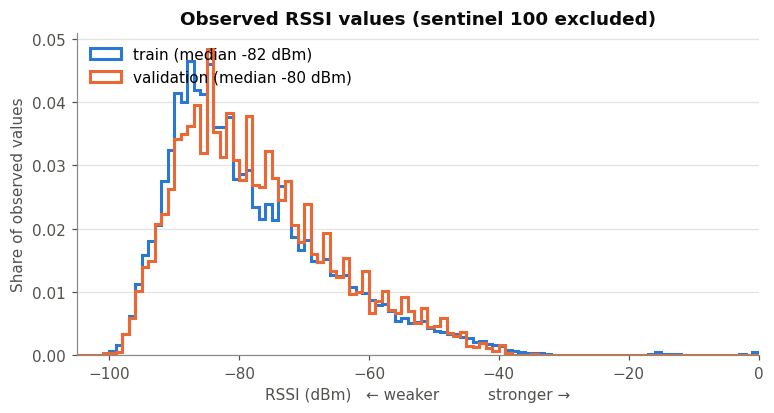

In [22]:
bins = np.arange(-105, 1, 1)
fig, ax = plt.subplots(figsize=(8, 3.8))
for split, v in [("train", obs_tr), ("validation", obs_va)]:
    ax.hist(v, bins=bins, density=True, histtype="step", linewidth=2,
            color=SPLIT_COLORS[split], label=f"{split} (median {np.median(v):.0f} dBm)")
ax.set_xlabel("RSSI (dBm)   ← weaker          stronger →")
ax.set_ylabel("Share of observed values")
ax.set_title("Observed RSSI values (sentinel 100 excluded)")
ax.legend(loc="upper left")
ax.set_xlim(-105, 0)
save(fig, "rssi_distribution")
plt.show()

Most detected signals are weak (median −82 dBm in train, −80 dBm in validation; 95% are weaker than −54 dBm): a phone hears many distant access points and only
a few nearby ones. The strong tail is informative, because a strong signal means the phone is close to
that AP.

This also explains the imputation choice for Member 3: replacing `100` with a value **below** the weakest
real reading (e.g. −105 or −110 dBm) keeps the order *not detected < weakest detected*. Leaving `100` in
place would tell a model that "not detected" is the strongest signal possible.

### 5.2 Access points detected per scan, and the strongest signal per scan

saved results/figures/eda_aps_per_scan.png


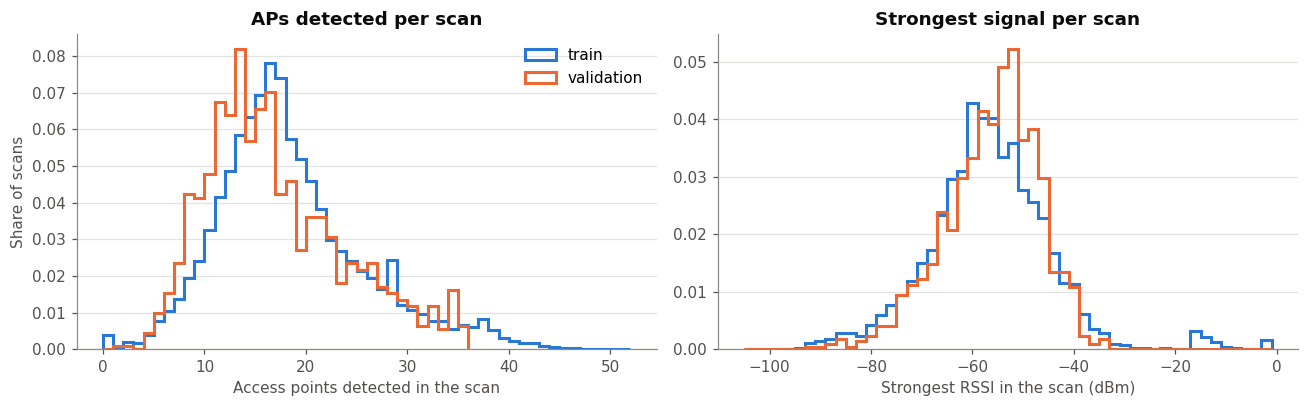

scans  median_aps  mean_aps  median_strongest_dBm
split      BUILDINGID                                                   
train      0            5249        16.0      15.8                 -55.0
           1            5196        15.0      16.6                 -61.0
           2            9492        19.0      20.0                 -57.0
validation 0             536        16.0      17.1                 -55.0
           1             307        13.0      14.0                 -57.0
           2             268        16.0      18.1                 -55.5

In [23]:
def strongest(X):
    """Strongest observed RSSI in each scan (NaN for scans with nothing detected)."""
    return X.where(X != MISSING_RSSI).max(axis=1)

per_scan = pd.concat([
    pd.DataFrame({"split": "train", "BUILDINGID": train["BUILDINGID"],
                  "aps_detected": n_detected(X_tr), "strongest_rssi": strongest(X_tr)}),
    pd.DataFrame({"split": "validation", "BUILDINGID": val["BUILDINGID"],
                  "aps_detected": n_detected(X_va), "strongest_rssi": strongest(X_va)}),
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for split in ["train", "validation"]:
    d = per_scan[per_scan["split"] == split]
    axes[0].hist(d["aps_detected"], bins=np.arange(0, d["aps_detected"].max() + 2), density=True,
                 histtype="step", linewidth=2, color=SPLIT_COLORS[split], label=split)
    axes[1].hist(d["strongest_rssi"].dropna(), bins=np.arange(-105, 1, 2), density=True,
                 histtype="step", linewidth=2, color=SPLIT_COLORS[split], label=split)
axes[0].set_xlabel("Access points detected in the scan")
axes[0].set_ylabel("Share of scans")
axes[0].set_title("APs detected per scan")
axes[1].set_xlabel("Strongest RSSI in the scan (dBm)")
axes[1].set_title("Strongest signal per scan")
axes[0].legend(loc="upper right")
fig.tight_layout()
save(fig, "aps_per_scan")
plt.show()

(per_scan.groupby(["split", "BUILDINGID"])
         .agg(scans=("aps_detected", "size"),
              median_aps=("aps_detected", "median"),
              mean_aps=("aps_detected", "mean"),
              median_strongest_dBm=("strongest_rssi", "median"))
         .round(1))

These two quantities are exactly the aggregate features Member 3 will engineer (**signal count** and
**strongest RSSI**). If they differ by building, they carry location information on their own: for
example, a building with denser AP coverage produces scans with more detections.

### 5.2b Implausibly strong readings

The strongest-signal histogram shows a small cluster of training scans between −20 and 0 dBm that does
not exist in validation (whose strongest reading is −34 dBm). Readings that strong are physically
unusual for a phone a normal distance from an access point, so we check where they come from.

In [24]:
STRONG = -30  # dBm; stronger than this is treated as suspicious

strong_mask = (X_tr != MISSING_RSSI) & (X_tr > STRONG)
scans_with_strong = strong_mask.any(axis=1)
print(f"Readings stronger than {STRONG} dBm: {int(strong_mask.values.sum()):,} "
      f"in {int(scans_with_strong.sum()):,} training scans ({scans_with_strong.mean() * 100:.1f}%)")
print(f"Validation readings stronger than {STRONG} dBm: "
      f"{int(((X_va != MISSING_RSSI) & (X_va > STRONG)).values.sum())}")

by_device = (train.loc[scans_with_strong]
                  .groupby(["USERID", "PHONEID"]).size().rename("scans with strong readings")
                  .to_frame()
                  .join(train.groupby(["USERID", "PHONEID"]).size().rename("all scans by device"))
                  .sort_values("scans with strong readings", ascending=False))
by_device["share of device's scans (%)"] = (by_device.iloc[:, 0] / by_device.iloc[:, 1] * 100).round(1)
by_device

Readings stronger than -30 dBm: 775 in 492 training scans (2.5%)
Validation readings stronger than -30 dBm: 0


,,scans with strong readings,all scans by device,share of device's scans (%)
USERID,PHONEID,,,
6,19,430,980,43.9
14,7,51,1596,3.2
3,16,5,192,2.6
10,8,2,913,0.2
15,11,2,498,0.4
1,14,1,2737,0.0
16,14,1,1032,0.1


**Finding:** 775 readings stronger than −30 dBm occur in 492 training scans (2.5%), and none in validation.
**430 of those 492 scans (87%) come from a single device, USERID 6 with PHONEID 19**, where they affect 44%
of that device's scans. This is a device artefact, not genuine proximity to access points.
Recommendation for Member 3: clip readings at −30 dBm (or test with and without that device's scans),
since no validation phone produces readings like these.

### 5.3 Where the scans were taken

Unique train reference points: 933   validation points: 1,074
saved results/figures/eda_map_by_building.png


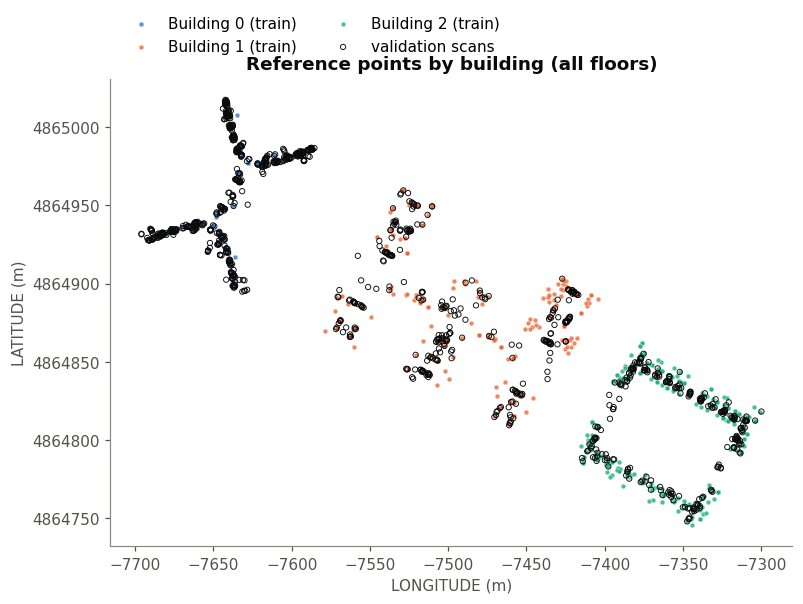

In [25]:
# One dot per reference point (unique location) keeps the maps readable
pts_tr = train.drop_duplicates(["LONGITUDE", "LATITUDE", "FLOOR"])
pts_va = val.drop_duplicates(["LONGITUDE", "LATITUDE", "FLOOR"])
print(f"Unique train reference points: {len(pts_tr):,}   validation points: {len(pts_va):,}")

fig, ax = plt.subplots(figsize=(8, 6))
for b, c in BUILDING_COLORS.items():
    d = pts_tr[pts_tr["BUILDINGID"] == b]
    ax.scatter(d["LONGITUDE"], d["LATITUDE"], s=10, color=c, alpha=0.8,
               edgecolors="white", linewidths=0.3, label=f"Building {b} (train)")
ax.scatter(pts_va["LONGITUDE"], pts_va["LATITUDE"], s=12, facecolors="none",
           edgecolors="#0b0b0b", linewidths=0.6, label="validation scans")
ax.set_aspect("equal")
ax.grid(visible=False)
ax.set_xlabel("LONGITUDE (m)")
ax.set_ylabel("LATITUDE (m)")
ax.set_title("Reference points by building (all floors)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, borderaxespad=0.6)
ax.ticklabel_format(useOffset=False, style="plain")
save(fig, "map_by_building")
plt.show()

The coordinates are projected positions in metres, so distances on this map are real distances and
Euclidean error (Member 5) is measured in metres. The three buildings are spatially separate, which is
why building classification is expected to be the easiest of the three tasks.

saved results/figures/eda_map_by_floor.png


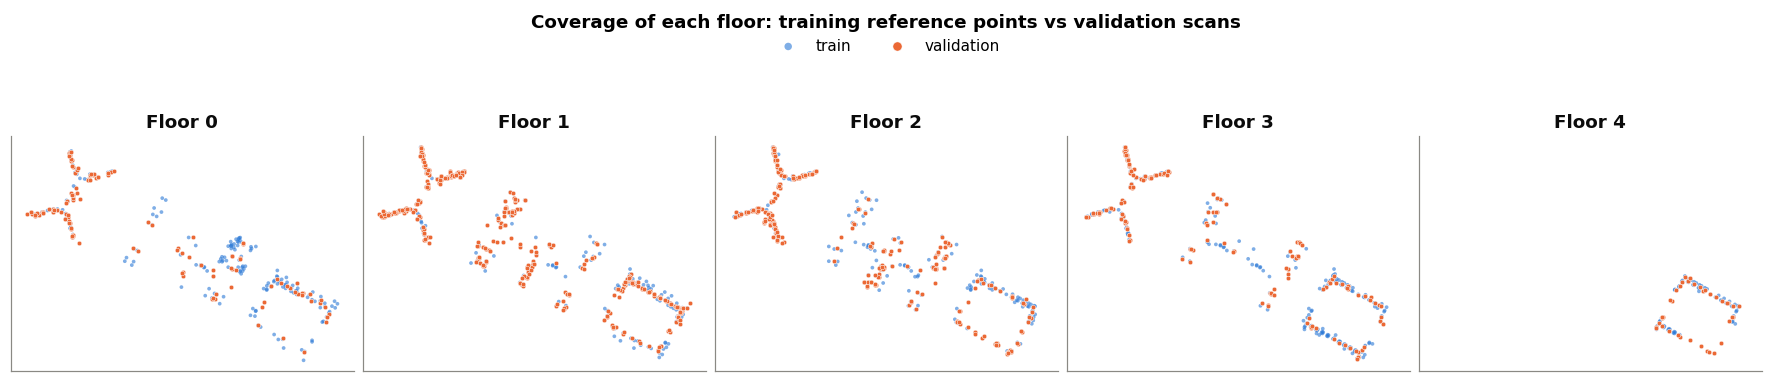

In [26]:
floors = sorted(train["FLOOR"].unique())
fig, axes = plt.subplots(1, len(floors), figsize=(16, 4), sharex=True, sharey=True, layout="constrained")
for ax, f in zip(axes, floors):
    t = pts_tr[pts_tr["FLOOR"] == f]
    v = pts_va[pts_va["FLOOR"] == f]
    ax.scatter(t["LONGITUDE"], t["LATITUDE"], s=6, color=SPLIT_COLORS["train"], alpha=0.6,
               edgecolors="none", label="train")
    ax.scatter(v["LONGITUDE"], v["LATITUDE"], s=9, color=SPLIT_COLORS["validation"],
               edgecolors="white", linewidths=0.3, label="validation")
    ax.set_title(f"Floor {f}")
    ax.set_aspect("equal")
    ax.grid(visible=False)
    ax.set_xticks([])
    ax.set_yticks([])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2, markerscale=2,
           title="Coverage of each floor: training reference points vs validation scans",
           title_fontproperties={"weight": "bold", "size": 12})
save(fig, "map_by_floor")
plt.show()

This view shows whether validation scans fall inside areas that training covers. Validation scans
located away from any training point have no nearby reference fingerprints, so larger positioning
errors are expected there. The next cell quantifies that.

**Finding:** the reference points follow the corridors of each building (one dot per position, 933 in
training). Validation scans are mostly close to training points: the median gap to the nearest training
point on the same floor is **0.9 m** and 90% are within 4.6 m. However, **35 validation scans (3.2%) are
more than 10 m from any training point** (the furthest is 45.7 m away). Expect the largest positioning
errors at those scans; Member 5 can check this in the failure analysis.

In [27]:
from scipy.spatial import cKDTree

# Distance from each validation scan to the nearest training reference point on the same building and floor.
# This uses validation coordinates only to DESCRIBE coverage; it is not used to train or tune anything.
gaps = []
for (b, f), v in val.groupby(["BUILDINGID", "FLOOR"]):
    t = pts_tr[(pts_tr["BUILDINGID"] == b) & (pts_tr["FLOOR"] == f)]
    tree = cKDTree(t[["LONGITUDE", "LATITUDE"]].values)
    d, _ = tree.query(v[["LONGITUDE", "LATITUDE"]].values)
    gaps.append(pd.DataFrame({"BUILDINGID": b, "FLOOR": f, "gap_m": d}))
gaps = pd.concat(gaps, ignore_index=True)

print("Distance (m) from a validation scan to the nearest training reference point, same floor:")
print(gaps["gap_m"].describe(percentiles=[0.5, 0.9]).round(1).to_string())
print(f"\nValidation scans more than 10 m from any training point: "
      f"{(gaps['gap_m'] > 10).sum()} ({(gaps['gap_m'] > 10).mean() * 100:.1f}%)")

Distance (m) from a validation scan to the nearest training reference point, same floor:
count    1111.0
mean        2.0
std         3.7
min         0.0
50%         0.9
90%         4.6
max        45.7

Validation scans more than 10 m from any training point: 35 (3.2%)


### 5.4 Access-point coverage across the campus

saved results/figures/eda_map_ap_coverage.png


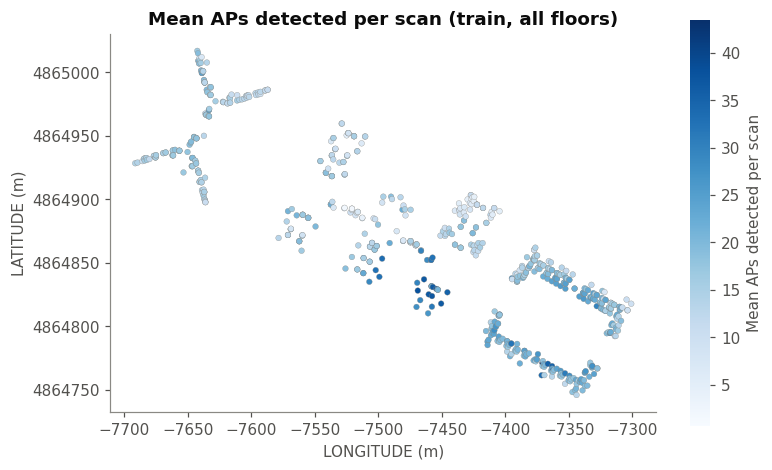

In [28]:
cov = (train[["LONGITUDE", "LATITUDE"]].assign(aps=n_detected(X_tr))
            .groupby(["LONGITUDE", "LATITUDE"], as_index=False)["aps"].mean())

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(cov["LONGITUDE"], cov["LATITUDE"], c=cov["aps"], cmap="Blues",
                s=14, edgecolors="#8a8984", linewidths=0.2)
cb = fig.colorbar(sc, ax=ax, shrink=0.8)
cb.set_label("Mean APs detected per scan")
cb.outline.set_visible(False)
ax.set_aspect("equal")
ax.grid(visible=False)
ax.set_xlabel("LONGITUDE (m)")
ax.set_ylabel("LATITUDE (m)")
ax.set_title("Mean APs detected per scan (train, all floors)")
ax.ticklabel_format(useOffset=False, style="plain")
save(fig, "map_ap_coverage")
plt.show()

Pale areas are places where phones detect few access points. Fingerprints there are less distinctive,
so these are the areas where Member 5's error maps are most likely to show large positioning errors.

**Finding:** coverage varies a lot across campus. A cluster in the south of building 1 detects 35–40 APs
per scan, while parts of the north of building 1 detect around 10 or fewer. Building 2 has the densest
coverage overall (median 19 APs per scan vs 15–16 in buildings 0 and 1).

## Stage 3 findings

| Check | Result | Implication |
|---|---|---|
| Observed RSSI | Median −82 dBm (train), −80 dBm (validation); 95% weaker than −54 dBm | Most detections are weak and distant |
| Imputation value | Weakest real reading is −104 dBm | Member 3 should map `100` below this (e.g. −105 or −110) |
| APs per scan | Median 17 (train), 15 (validation); building 2 median 19, buildings 0–1 15–16 | Signal count carries building information |
| Strongest signal per scan | Median about −55 to −61 dBm across buildings | Useful aggregate feature for Member 3 |
| Very strong readings | Train contains readings up to 0 dBm; validation never exceeds −34 dBm | See 5.2b: likely a device artefact; consider clipping at −30 dBm |
| Reference points | 933 unique training positions along corridors | Fingerprints are spatially discrete, not a uniform grid |
| Validation coverage | Median gap to nearest train point 0.9 m; 90% within 4.6 m; 35 scans (3.2%) more than 10 m away, max 45.7 m | Most test scans are well covered; a few are not |
| Low-coverage areas | North of building 1 detects around 10 or fewer APs per scan | Expect larger errors there |

## 6. Users, devices, train vs validation shift, and leakage risks

The metadata columns are never model inputs, but they decide **how we validate fairly**: who collected
which areas, with which phone and when determines what a fair split looks like.

### 6.1 Who collected the training data, and where

saved results/figures/eda_users_and_phones.png


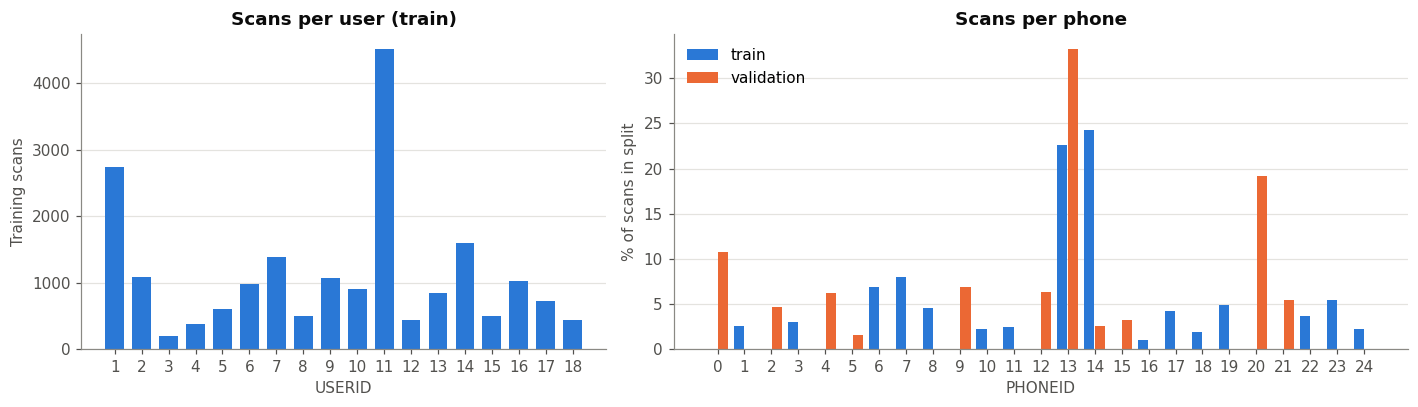

Phones only in train:      [1, 3, 6, 7, 8, 10, 11, 16, 17, 18, 19, 22, 23, 24]
Phones only in validation: [0, 2, 4, 5, 9, 12, 15, 20, 21]
Phones in both:            [13, 14]


In [29]:
users = train["USERID"].value_counts().sort_index()
phones_tr = train["PHONEID"].value_counts().sort_index()
phones_va = val["PHONEID"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].bar(users.index.astype(str), users.values, color=SPLIT_COLORS["train"], width=0.7)
axes[0].set_xlabel("USERID")
axes[0].set_ylabel("Training scans")
axes[0].set_title("Scans per user (train)")

all_phones = sorted(set(phones_tr.index) | set(phones_va.index))
x = np.arange(len(all_phones))
tr_pct = phones_tr.reindex(all_phones, fill_value=0) / len(train) * 100
va_pct = phones_va.reindex(all_phones, fill_value=0) / len(val) * 100
w = 0.38
axes[1].bar(x - (w + 0.02) / 2, tr_pct, width=w, color=SPLIT_COLORS["train"], label="train")
axes[1].bar(x + (w + 0.02) / 2, va_pct, width=w, color=SPLIT_COLORS["validation"], label="validation")
axes[1].set_xticks(x, [str(p) for p in all_phones])
axes[1].set_xlabel("PHONEID")
axes[1].set_ylabel("% of scans in split")
axes[1].set_title("Scans per phone")
axes[1].legend(loc="upper left")
fig.tight_layout()
save(fig, "users_and_phones")
plt.show()

print("Phones only in train:     ", sorted(set(phones_tr.index) - set(phones_va.index)))
print("Phones only in validation:", sorted(set(phones_va.index) - set(phones_tr.index)))
print("Phones in both:           ", sorted(set(phones_tr.index) & set(phones_va.index)))

saved results/figures/eda_user_coverage.png


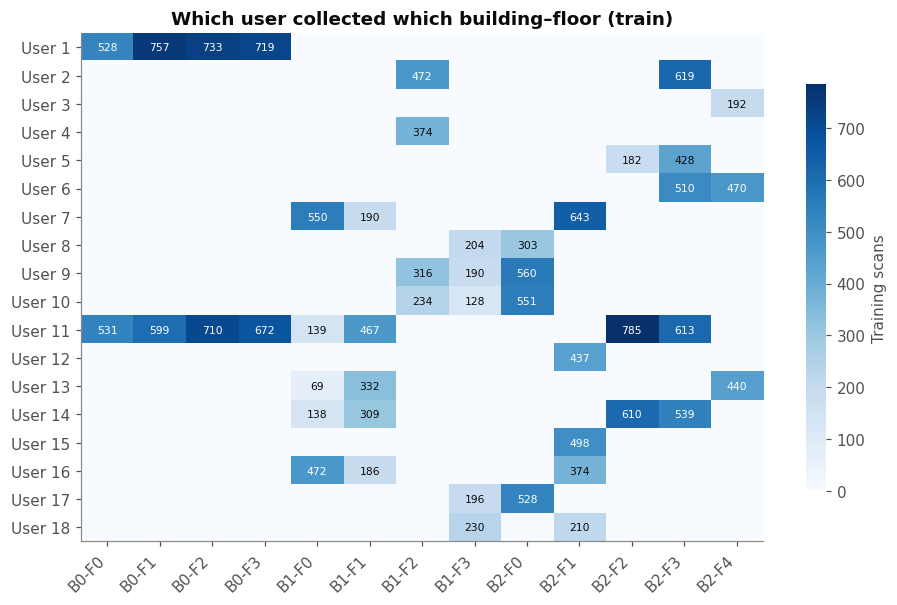

,scans,% of train,buildings covered,building–floors covered,phones used
USERID,,,,,
1,2737,13.7,1,4,1
2,1091,5.5,2,2,1
3,192,1.0,1,1,1
4,374,1.9,1,1,1
5,610,3.1,1,2,1
6,980,4.9,1,2,1
7,1383,6.9,2,3,1
8,507,2.5,2,2,1
9,1066,5.3,2,3,1


In [30]:
# Which building-floor areas did each user cover?
cover = pd.crosstab(train["USERID"],
                    "B" + train["BUILDINGID"].astype(str) + "-F" + train["FLOOR"].astype(str))

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(cover.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(cover.shape[1]), cover.columns, rotation=45, ha="right")
ax.set_yticks(range(cover.shape[0]), [f"User {u}" for u in cover.index])
ax.grid(visible=False)
for i in range(cover.shape[0]):
    for j in range(cover.shape[1]):
        n = cover.values[i, j]
        if n:
            ax.text(j, i, n, ha="center", va="center", fontsize=7,
                    color="white" if n > cover.values.max() * 0.55 else "#0b0b0b")
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Training scans")
cb.outline.set_visible(False)
ax.set_title("Which user collected which building–floor (train)")
save(fig, "user_coverage")
plt.show()

per_user = pd.DataFrame({
    "scans": users,
    "% of train": (users / len(train) * 100).round(1),
    "buildings covered": train.groupby("USERID")["BUILDINGID"].nunique(),
    "building–floors covered": (cover > 0).sum(axis=1),
    "phones used": train.groupby("USERID")["PHONEID"].nunique(),
})
per_user

**Finding:** collection was divided by area, not repeated by everyone everywhere.
- Each user covered only **1 to 8 of the 13 building–floors** (most covered 1–3), and each user used
  **exactly one phone**, so in training, user and phone are the same grouping.
- User 11 alone contributed 22.7% of training scans across 8 building–floors; user 1 contributed 13.7%,
  all in building 0.
- Training used 16 phones and validation 11, with only **PHONEID 13 and 14 in both**.

**Why this matters for validation:** holding out a user also removes most of the training data for the
areas that user covered. A user-grouped split therefore tests a harder problem (new person, new phone and
partly unfamiliar areas) than the official split does. See the numbers in 6.5.

### 6.2 Device differences

saved results/figures/eda_phone_differences.png


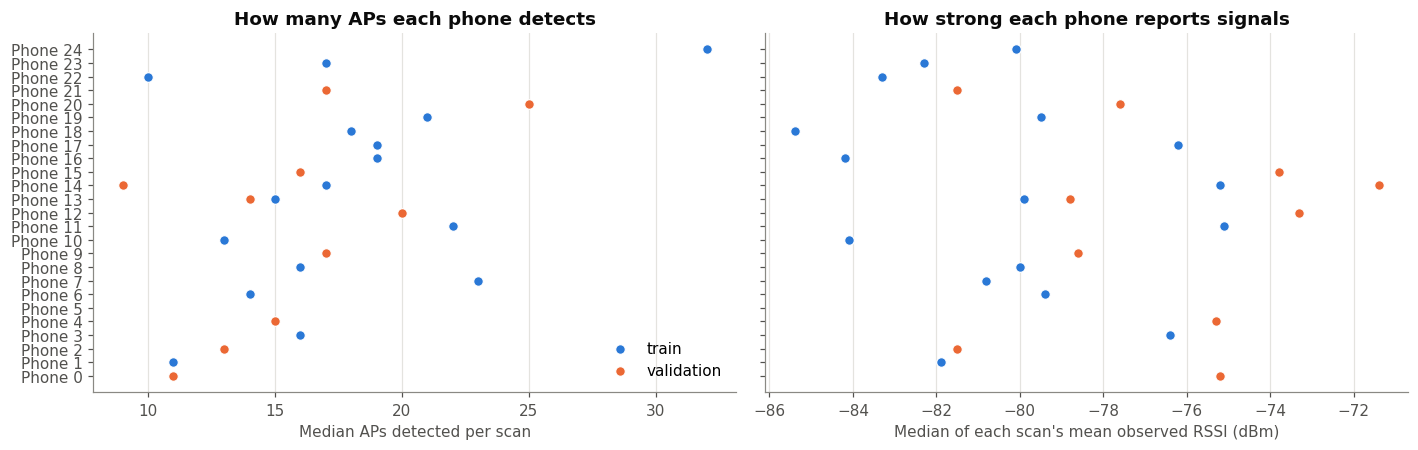

In [31]:
def phone_profile(df, X, split):
    obs = X.where(X != MISSING_RSSI)
    return pd.DataFrame({
        "split": split,
        "PHONEID": df["PHONEID"].values,
        "aps_detected": n_detected(X).values,
        "mean_observed_rssi": obs.mean(axis=1).values,
    })

prof = pd.concat([phone_profile(train, X_tr, "train"), phone_profile(val, X_va, "validation")])
phone_summary = (prof.groupby(["PHONEID", "split"])
                     .agg(scans=("aps_detected", "size"),
                          median_aps=("aps_detected", "median"),
                          median_mean_rssi=("mean_observed_rssi", "median"))
                     .round(1)
                     .reset_index())
phone_summary.to_csv(METRICS_DIR / "eda_phone_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for split in ["train", "validation"]:
    d = phone_summary[(phone_summary["split"] == split) & (phone_summary["scans"] >= 20)]
    y = [all_phones.index(p) for p in d["PHONEID"]]
    axes[0].scatter(d["median_aps"], y, s=40, color=SPLIT_COLORS[split],
                    edgecolors="white", linewidths=0.8, label=split, zorder=3)
    axes[1].scatter(d["median_mean_rssi"], y, s=40, color=SPLIT_COLORS[split],
                    edgecolors="white", linewidths=0.8, label=split, zorder=3)
axes[0].set_yticks(range(len(all_phones)), [f"Phone {p}" for p in all_phones])
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
axes[0].set_xlabel("Median APs detected per scan")
axes[1].set_xlabel("Median of each scan's mean observed RSSI (dBm)")
axes[0].set_title("How many APs each phone detects")
axes[1].set_title("How strong each phone reports signals")
axes[0].legend(loc="lower right")
fig.tight_layout()
save(fig, "phone_differences")
plt.show()

Phones with at least 20 scans are shown. Different Wi-Fi chips and antennas detect different numbers of
access points and report systematically stronger or weaker RSSI at the same place. Since only 2 of the 11
validation phones appear in training, a model must cope with RSSI offsets it never saw. This is a strong
argument for features that are robust to a constant offset, such as **missingness indicators** and
rank or relative-strength features (Member 3).

**Finding:** the differences between phones are large. The median number of APs detected per scan ranges
from about 9 to 32 depending on the phone, and the typical reported signal strength ranges from about
−86 to −71 dBm, a spread of roughly 15 dB. A model that has only seen a few phones can easily
misinterpret a new phone's systematic offset as a change of location.

### 6.3 When the data was collected

saved results/figures/eda_collection_timeline.png


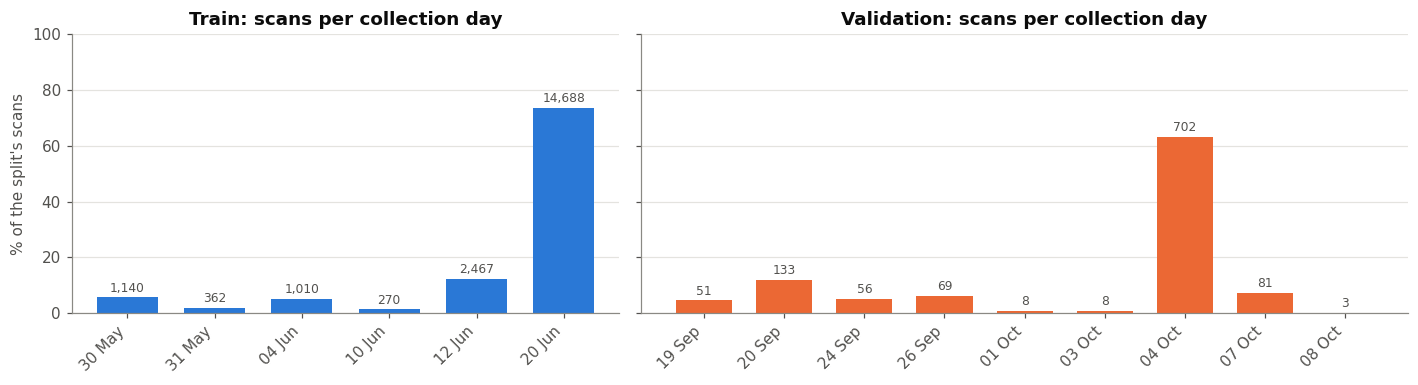

Train collection days:      6 (30 May 2013 to 20 Jun 2013)
Validation collection days: 9 (19 Sep 2013 to 08 Oct 2013)
Gap between last train day and first validation day: 91 days
Busiest train day: 20 Jun 2013 with 14,688 scans (73.7% of train)


In [37]:
days = pd.concat([
    pd.DataFrame({"split": "train", "day": pd.to_datetime(train["TIMESTAMP"], unit="s").dt.floor("D")}),
    pd.DataFrame({"split": "validation", "day": pd.to_datetime(val["TIMESTAMP"], unit="s").dt.floor("D")}),
])
per_day = days.groupby(["split", "day"]).size()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True,
                         gridspec_kw={"width_ratios": [1, 1.4]})
for ax, split in zip(axes, ["train", "validation"]):
    s = per_day[split]
    pct = s / s.sum() * 100
    bars = ax.bar(range(len(s)), pct.values, width=0.7, color=SPLIT_COLORS[split])
    for b, n in zip(bars, s.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{n:,}",
                ha="center", va="bottom", fontsize=8, color=TEXT)
    ax.set_xticks(range(len(s)), [d.strftime("%d %b") for d in s.index], rotation=45, ha="right")
    ax.set_title(f"{split.capitalize()}: scans per collection day")
axes[0].set_ylabel("% of the split's scans")
axes[0].set_ylim(0, 100)
fig.tight_layout()
save(fig, "collection_timeline")
plt.show()

train_days = per_day["train"].index
val_days = per_day["validation"].index
print("Train collection days:     ", len(train_days), f"({train_days.min():%d %b %Y} to {train_days.max():%d %b %Y})")
print("Validation collection days:", len(val_days), f"({val_days.min():%d %b %Y} to {val_days.max():%d %b %Y})")
print("Gap between last train day and first validation day:", (val_days.min() - train_days.max()).days, "days")
print(f"Busiest train day: {per_day['train'].idxmax():%d %b %Y} with {per_day['train'].max():,} scans "
      f"({per_day['train'].max() / len(train) * 100:.1f}% of train)")

Wi-Fi environments change over time: access points are moved, replaced, or switched off, and furniture
and occupancy change. The months-long gap between the two collections is one reason some access points
appear in only one file (section 3.5).

**Finding:** training was collected on 6 days and validation on 9 days, with a **91-day gap** between
them. Both collections are concentrated: 20 June 2013 alone accounts for 73.7% of training scans (14,688),
and 4 October 2013 for 63% of validation scans (702). Each file is therefore dominated by one large
collection session, which makes the session-to-session differences between the files more pronounced.

### 6.4 Train vs validation: input distributions only (no labels)

saved results/figures/eda_wap_detection_train_vs_val.png


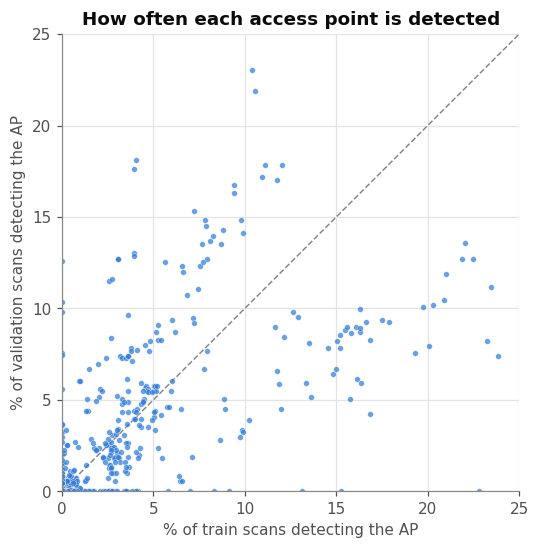

Correlation of per-AP detection rates (train vs validation): 0.64


In [33]:
from scipy.stats import ks_2samp

det_rate = pd.DataFrame({
    "train": (X_tr != MISSING_RSSI).mean() * 100,
    "validation": (X_va != MISSING_RSSI).mean() * 100,
})

fig, ax = plt.subplots(figsize=(5.8, 5.4))
lim = det_rate.values.max() * 1.05
ax.plot([0, lim], [0, lim], color="#8a8984", linewidth=1, linestyle="--", zorder=1)
ax.scatter(det_rate["train"], det_rate["validation"], s=14, color=SPLIT_COLORS["train"],
           alpha=0.7, edgecolors="white", linewidths=0.3, zorder=2)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.grid(axis="x", visible=True)
ax.set_xlabel("% of train scans detecting the AP")
ax.set_ylabel("% of validation scans detecting the AP")
ax.set_title("How often each access point is detected")
save(fig, "wap_detection_train_vs_val")
plt.show()

print(f"Correlation of per-AP detection rates (train vs validation): "
      f"{det_rate['train'].corr(det_rate['validation']):.2f}")

Each dot is one access point. Dots on the dashed line are detected equally often in both files. Dots on
the axes are APs seen in only one file. A rough diagonal trend means the same infrastructure is mostly
present in both, but individual APs can differ a lot.

The comparison below uses **only the inputs**, never the validation labels, so it is fair to report.

In [34]:
def ks(a, b):
    r = ks_2samp(a, b)
    return round(r.statistic, 3), f"{r.pvalue:.1e}"

shift = pd.DataFrame([
    ("APs detected per scan", *ks(n_detected(X_tr), n_detected(X_va))),
    ("Strongest RSSI per scan", *ks(strongest(X_tr).dropna(), strongest(X_va).dropna())),
    ("All observed RSSI values", *ks(obs_tr, obs_va)),
], columns=["quantity", "KS statistic", "p-value"]).set_index("quantity")
shift.to_csv(METRICS_DIR / "eda_train_val_shift.csv")
shift

,KS statistic,p-value
quantity,,
APs detected per scan,0.131,3.1e-16
Strongest RSSI per scan,0.079,4.2e-06
All observed RSSI values,0.057,4.0e-49


The **Kolmogorov–Smirnov (KS) statistic** is the largest gap between the two cumulative distributions
(0 = identical, 1 = completely separate). With samples this large, almost any difference is
"statistically significant", so read the **size** of the KS statistic, not the p-value: values below
about 0.1 indicate small shifts.

**Finding:** the per-AP detection rates of the two files are only moderately correlated (r = 0.64): many
APs are detected far more often in one file than the other. The number of APs per scan shows a
moderate shift (KS = 0.13; validation scans detect fewer APs), while the strongest signal (KS = 0.08)
and the overall RSSI distribution (KS = 0.06) shift only slightly.

### 6.5 Leakage risks

In [35]:
# (a) How many scans share the same reference point (exact position + floor)?
point_key = train[["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]].astype(str).agg("|".join, axis=1)
scans_per_point = point_key.value_counts()
print(f"Training reference points: {len(scans_per_point):,}; "
      f"median scans per point: {int(scans_per_point.median())}")

# (b) Were reference points visited by more than one user or phone?
users_per_point = train.groupby(point_key)["USERID"].nunique()
print(f"Reference points covered by more than one user: {(users_per_point > 1).mean() * 100:.1f}%")

# (c) Does any validation fingerprint appear exactly in training?
fp_tr = set(map(tuple, X_tr.values))
same_fp_val = sum(tuple(r) in fp_tr for r in X_va.values)
print(f"Validation fingerprints identical to a training fingerprint: {same_fp_val}")

Training reference points: 933; median scans per point: 20
Reference points covered by more than one user: 77.9%
Validation fingerprints identical to a training fingerprint: 0


In [36]:
# (d) What a random split would do: share of validation-fold scans whose exact position also appears in the training fold
from sklearn.model_selection import KFold, GroupKFold

def position_overlap(splitter, groups=None):
    shares = []
    for tr_idx, te_idx in splitter.split(train, groups=groups):
        seen = set(point_key.iloc[tr_idx])
        shares.append(np.mean([k in seen for k in point_key.iloc[te_idx]]))
    return round(np.mean(shares) * 100, 1)

print(f"Random 5-fold:            {position_overlap(KFold(5, shuffle=True, random_state=42))}% "
      "of held-out scans sit on a position already in the training fold")
print(f"GroupKFold by position:   {position_overlap(GroupKFold(5), groups=point_key)}%")
print(f"GroupKFold by USERID:     {position_overlap(GroupKFold(5), groups=train['USERID'])}%")

Random 5-fold:            100.0% of held-out scans sit on a position already in the training fold
GroupKFold by position:   0.0%
GroupKFold by USERID:     67.3%


**Leakage risks and how to handle them**

| Risk | Evidence | Recommendation |
|---|---|---|
| **Repeated scans at the same point** | 933 reference points with a median of 20 scans each. A random 5-fold puts **100%** of held-out scans on a position already in the training fold | Use the official validation file for final results. For cross-validation inside train, group by reference point or by user, not random K-fold |
| **Exact duplicate rows** | 637 in train (section 3.3) | Drop before splitting, or keep all copies in the same fold |
| **Location proxies as features** | `SPACEID` and `RELATIVEPOSITION` describe the room, i.e. the answer | Never use as model inputs |
| **Identity / time metadata** | `USERID`, `PHONEID`, `TIMESTAMP` are 0 or unseen values in validation | Not model inputs; use only for grouped splits and robustness analysis |
| **Preprocessing fitted on validation** | Imputation values, scaling statistics and dropped columns could be derived from validation | Fit every transform on training data only (Member 3's pipeline) |
| **Tuning on validation** | Validation labels are visible in the file | Tune with grouped CV inside train; touch validation once, for final results |
| **Peeking through the EDA** | This notebook shows validation label distributions | Descriptive only; none of these numbers feeds a modelling choice |

**Finding:** random K-fold inside train is effectively leakage: every held-out scan has 19 near-identical
siblings in the training fold, so it would report unrealistically good accuracy. Grouping by position
removes this completely (0% overlap). Grouping by user is in between: 67.3% of held-out scans still sit on
positions another user fingerprinted, because 77.9% of reference points were covered by more than one user.
No validation fingerprint is identical to a training fingerprint, so the official split has no direct leakage.

**Recommended validation strategy:**
1. **Final results:** train on the training file, evaluate once on `validationData.csv` (benchmark protocol).
2. **Hyperparameter tuning:** `GroupKFold` inside train, grouped by reference point. This is the honest
   in-train equivalent of locating scans at unseen positions.
3. **Robustness experiment:** `GroupKFold` by `USERID`, which (since each user used one phone) also tests
   generalisation to a new device. Report it as a harder, complementary result.

## 7. Summary and recommendations for the team

**One row of the data** is one Wi-Fi scan: 520 RSSI values (most of them "not detected") plus the true
building, floor and coordinates.

**The data is reliable:** no corrupted RSSI values, valid labels, spatially separate buildings, and every
building–floor class has at least 948 training scans at 50+ reference points.

**The data is hard because of:**
1. **Sparsity:** 96.5% of WAP cells are "not detected"; a typical scan sees about 17 of 520 APs.
2. **Shift between the files:** a 91-day gap, only 2 of 11 validation phones seen in training, a different
   building mix (train mostly building 2, validation mostly building 0), and 55 APs present only in validation.
   Validation scores will be lower than in-train cross-validation scores; this is expected.
3. **Device heterogeneity:** phones differ by roughly 15 dB in typical signal strength and detect from about
   9 to 32 APs per scan; one device (phone 19) produces implausibly strong readings.

**Recommendations**

| For | Recommendation |
|---|---|
| Member 3 (preprocessing) | Map `100` to a value below −104 (e.g. −110); add missingness indicators; drop the 55 constant WAPs; remove the 76 zero-AP scans; decide on the 637 duplicates; clip readings above −30 dBm (phone 19 artefact); add APs-detected and strongest-RSSI features; fit everything on train only |
| Member 4 (classical models) | Beat the majority-class baselines (building 47.6%, floor 25.3%); never tune with random K-fold (100% position overlap); tune with GroupKFold by reference point; run a USERID-grouped robustness test |
| Member 5 (evaluation) | Report macro-F1 and per-class recall; break results down by building (validation is 48% building 0) and by phone; check whether the 35 validation scans more than 10 m from any training point drive the largest errors |
| Whole team | Use `validationData.csv` once, for final reported results only |